In [2]:
import torch
import torch.nn as nn
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

In [3]:
print(torch.__version__)
print(torch.cuda.is_available())

2.5.1+cu124
True


In [4]:
train_dataset = datasets.MNIST(
    root="../data",
    train=True,
    download=True,
    transform=transforms.ToTensor()
)

test_dataset = datasets.MNIST(
    root="../data",
    train=False,
    download=True,
    transform=transforms.ToTensor()
)

In [5]:
train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)

In [46]:
images, labels = next(iter(train_loader))

print(images.shape)
print(labels.shape)
print(images.min().item())
print(images.max().item())

torch.Size([64, 1, 28, 28])
torch.Size([64])
0.0
1.0


In [7]:
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),  #16,28,28
            nn.ReLU(),
            nn.MaxPool2d(2,2)  #16,14,14
        )
        self.conv2 = nn.Sequential(
            nn.Conv2d(16, 32, kernel_size=3, padding=1),   #32,14,14
            nn.ReLU(),
            nn.MaxPool2d(2,2)   #32,7,7
        )
        self.fc1 = nn.Linear(32*7*7, 10)

    def forward(self, x):
        x = self.conv1(x)
        x = self.conv2(x)
        x = x.flatten(1)
        x = self.fc1(x)
        return x
        

In [8]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = CNN().to(device)

print(model)
print(device)

CNN(
  (conv1): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv2): Sequential(
    (0): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (fc1): Linear(in_features=1568, out_features=10, bias=True)
)
cuda


In [9]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.01
)


In [10]:
for epoch in range(10):
    
    model.train()
    
    total_loss = 0.0
    total_count = 0
    
    for inputs, labels in train_loader:
        inputs = inputs.to(device)
        labels = labels.to(device)
        optimizer.zero_grad()

        outputs = model(inputs)

        loss = loss_fn(outputs, labels)

        loss.backward()

        optimizer.step()

        total_count += labels.size(0)
        total_loss += loss.item() * labels.size(0)

    avg_loss = total_loss / total_count

    model.eval()
    val_count = 0
    correct = 0.0

    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)

            loss = loss_fn(outputs, labels)
            pre = outputs.argmax(dim=1)
            val_count += labels.size(0)
            correct += (pre == labels).sum().item()

        avg_correct = correct / val_count

    print("Epoch", epoch+1)
    print(f"avg loss:{ avg_loss:.5f}")
    print(f"avg correct:{avg_correct:.5f}")

Epoch 1
avg loss:0.16395
avg correct:0.97620
Epoch 2
avg loss:0.07247
avg correct:0.97780
Epoch 3
avg loss:0.06530
avg correct:0.97740
Epoch 4
avg loss:0.05813
avg correct:0.98160
Epoch 5
avg loss:0.05378
avg correct:0.98070
Epoch 6
avg loss:0.04987
avg correct:0.98020
Epoch 7
avg loss:0.04945
avg correct:0.98170
Epoch 8
avg loss:0.04884
avg correct:0.98460
Epoch 9
avg loss:0.04610
avg correct:0.98000
Epoch 10
avg loss:0.04346
avg correct:0.98380


In [11]:
torch.save(model.state_dict(),"best_model.pth")
print("save")

save


In [12]:
model.eval()

images, labels = next(iter(test_loader))   #take out a batch

images = images.to(device)
labels = labels.to(device)

with torch.no_grad():
    outputs = model(images)
    print("the shape of outputs:", outputs.shape)
    pre = outputs.argmax(dim=1)
    print("the shape of pre:", pre.shape)

correct_indices = (pre == labels).nonzero(as_tuple=True)[0]  #the first dim


print("the shape of correct:", correct_indices.shape)
if len(correct_indices) == 0:
    raise RuntimeError("time is out")

idx = correct_indices[0].item()

image = images[idx:idx + 1].detach().clone()  #切断梯度追踪，detach默认requires_grad=False,分离张量，使张量独立完整
label = labels[idx:idx + 1].detach().clone()

print(image.shape)
print(label.item())
print(pre[idx].item())

the shape of outputs: torch.Size([64, 10])
the shape of pre: torch.Size([64])
the shape of correct: torch.Size([62])
torch.Size([1, 1, 28, 28])
7
7


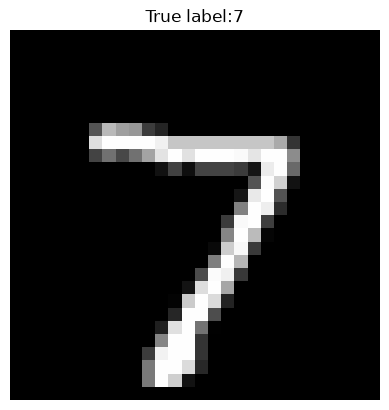

In [13]:
plt.imshow(image.detach().cpu().squeeze(), cmap="gray")
plt.title(f"True label:{label.item()}")
plt.axis("off")
plt.show()

In [14]:
image = image.detach().clone().requires_grad_(True)

model.zero_grad(set_to_none=True)

outputs = model(image)

loss = loss_fn(outputs, label)

loss.backward()

gradient = image.grad  #对于输入的梯度

print(loss.item())
print(gradient is not None)
print(gradient.shape)
print(gradient.min().item())
print(gradient.max().item())
print(torch.isfinite(gradient).all().item())

1.1920922133867862e-06
True
torch.Size([1, 1, 28, 28])
-9.319274795416277e-06
1.0683196705940645e-05
True


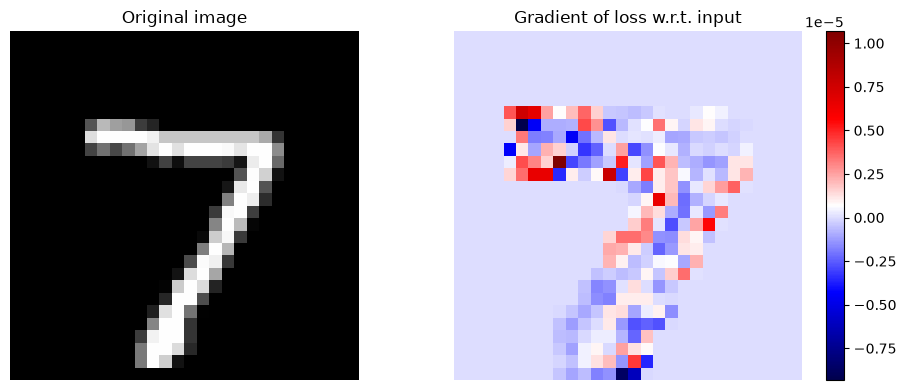

In [15]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(image.detach().cpu().squeeze(), cmap="gray")
plt.title("Original image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(
    gradient.detach().cpu().squeeze(),
    cmap="seismic"
)
plt.colorbar()
plt.title("Gradient of loss w.r.t. input")
plt.axis("off")

plt.tight_layout()
plt.show()

In [16]:
#生成扰动 (x + epsilon * gradient)

epsilon = 0.1

perturbation = epsilon * gradient.detach().sign()  #扰动

adversarial_image = image.detach() + perturbation   #原图加扰动

adversarial_image = adversarial_image.clamp(0, 1) #保持在【0,1】，小于0的直接用0代替，大于1的直接用1代替

actual_data = adversarial_image - image.detach()  #实际扰动

print("扰动预算：", epsilon)
print("实际最大扰动：", actual_data.abs().max().item())
print("扰动是否满足预算：", actual_data.abs().max().item() <= epsilon + 1e-6)
print("实际像素范围：", image.detach().abs().min().item(), image.detach().abs().max().item())
print("对抗图片像素范围：", adversarial_image.min().item(), adversarial_image.max().item())


扰动预算： 0.1
实际最大扰动： 0.10000002384185791
扰动是否满足预算： True
实际像素范围： 0.0 1.0
对抗图片像素范围： 0.0 1.0


In [17]:
model.eval()

with torch.no_grad():
    original_outputs = model(image.detach())
    original_prediction = original_outputs.argmax(dim=1).item()

epsilon = 0.1
perturbation = epsilon * gradient.detach().sign()
adversarial_image = (image.detach() + perturbation).clamp(0,1)

with torch.no_grad():
    adversarial_outputs = model(adversarial_image)
    adversarial_prediction = adversarial_outputs.argmax(dim=1).item()

print("真实标签：", label.item())
print("原始预测标签：", original_prediction)
print("对抗图片预测：", adversarial_prediction)
print("对抗是否成功", original_prediction != adversarial_prediction)

真实标签： 7
原始预测标签： 7
对抗图片预测： 9
对抗是否成功 True


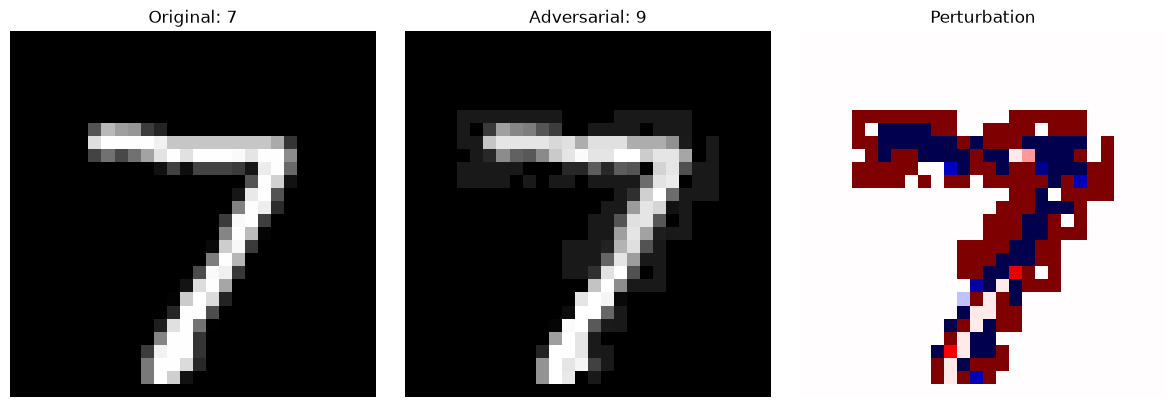

In [18]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(image.detach().cpu().squeeze(), cmap="gray", vmin=0, vmax=1)
plt.title(f"Original: {original_prediction}")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(
    adversarial_image.detach().cpu().squeeze(),
    cmap="gray",
    vmin=0,
    vmax=1
)
plt.title(f"Adversarial: {adversarial_prediction}")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(
    actual_data.detach().cpu().squeeze(),
    cmap="seismic",
    vmin=-epsilon,
    vmax=epsilon
)
plt.title("Perturbation")
plt.axis("off")

plt.tight_layout()
plt.show()

In [43]:
import pandas as pd
import matplotlib.pyplot as plt

epsilons = [0.0, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3]
results = []

model.eval()

for epsilon in epsilons:
    original_correct = 0.0  
    adv_correct = 0.0
    attack_success = 0.0
    total = 0

    for images, labels in test_loader:
        
        images = images.to(device)
        labels = labels.to(device)

        images = images.detach().clone().requires_grad_(True)
        model.zero_grad(set_to_none=True)

        outputs = model(images)
        loss = loss_fn(outputs, labels)

        loss.backward()

        gradient = images.grad.detach()

        original_prediction = outputs.detach().argmax(dim=1)
        original_mask = (original_prediction == labels)  #预测是否正确
        original_correct += original_mask.sum().item()   #原始预测正确率

        perturbed_images = (images.detach() + epsilon * gradient.sign()).clamp(0, 1) #扰动后的图片

        with torch.no_grad():
            adv_outputs = model(perturbed_images)  #对抗输出
            adv_prediction = adv_outputs.argmax(dim=1)  #对抗预测

        adv_mask = (adv_prediction == labels)  #对抗预测是否正确

        adv_correct += adv_mask.sum().item()  #对抗样本预测正确率

        attack_success += (original_mask & (~adv_mask)).sum().item()

        total += labels.size(0)
     
        
    original_accuracy = 100 * original_correct / total
    adv_accuracy = 100 * adv_correct / total
    success_rate = (100 * attack_success / original_correct if original_correct > 0 else 0.0)
    results.append({
        "epsilon": epsilon,
        "original_accuracy": original_accuracy,
        "adversarial_accuracy": adv_accuracy,
        "attack_success_rate": success_rate
    })

df = pd.DataFrame(results)
print(df.round(2).to_string(index=False))


 epsilon  original_accuracy  adversarial_accuracy  attack_success_rate
    0.00              98.38                 98.38                 0.00
    0.05              98.38                 77.35                21.38
    0.10              98.38                 47.38                51.84
    0.15              98.38                 34.34                65.09
    0.20              98.38                 27.45                72.10
    0.25              98.38                 23.28                76.35
    0.30              98.38                 20.34                79.34


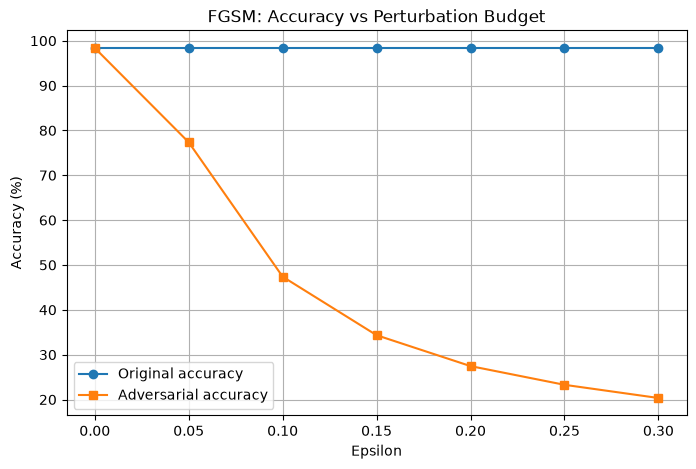

In [44]:

plt.figure(figsize=(8, 5))

plt.plot(
    df["epsilon"],
    df["original_accuracy"],
    marker="o",
    label="Original accuracy"
)

plt.plot(
    df["epsilon"],
    df["adversarial_accuracy"],
    marker="s",
    label="Adversarial accuracy"
)

plt.xlabel("Epsilon")
plt.ylabel("Accuracy (%)")
plt.title("FGSM: Accuracy vs Perturbation Budget")
plt.grid(True)
plt.legend()
plt.show()
